# 04 · How each fault shows in the data

**Goal:** for each of the four faults, say which signals should change and why (the physics), and check if the labelled events agree. Then look for faults without a label, and labels that are hard to see.

**How to read this notebook.** First the physics I expect. Then one section per fault with a real example. Then two checks on the labels: do the dates match the data, and is anything missing?

What I expect, in plain words (more in `docs/03 - AHU physics and faults.md`):

| Fault | Plain name | What breaks | What I expect to see |
|---|---|---|---|
| `chw_valve_stuck` | stuck tap | The cold water valve doesn't move any more | Supply air far from its setpoint. The controller pushes the valve command to 0% or 100%, with no effect |
| `oa_damper_stuck` | stuck flap | The outdoor air flap stays (almost) closed | Mixed air = return air (no outdoor air). CO2 goes up in the rooms. The controller opens the flap command more, with no effect |
| `sat_sensor_bias` | lying thermometer | The supply air sensor reads too high or too low | Hard: the controller trusts the sensor, so the reading stays on target. The real air is too cold or too warm |
| `low_coil_capacity` | weak radiator | The coil cools less for the same valve opening | The valve opens more than usual for the same cooling. When it reaches 100%, the supply air gets warm |

All signals come from `src/ahu_fdd/features.py`, each with a unit test.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

from ahu_fdd.config import FAULT_NAMES
from ahu_fdd.data import add_building, clean_sensors, label_rows, load_labels, load_sensors
from ahu_fdd.eda import event_vs_normal
from ahu_fdd.features import (
    cooling_per_valve,
    minutes_since_fan_on,
    outdoor_air_fraction,
    sat_error,
    sat_offset_at_rest,
)
from ahu_fdd.plots import FAULT_COLORS, save_fig, set_style

set_style()  # same look for every chart

In [2]:
# Cleaned train data with labels and the physics signals (all from src/ahu_fdd/features.py)
labels = load_labels()
train = add_building(clean_sensors(load_sensors("train")))
train["label"] = label_rows(train, labels)
train["minutes_on"] = minutes_since_fan_on(train)
train["sat_error"] = sat_error(train)  # supply air minus setpoint
train["oa_fraction"] = outdoor_air_fraction(train)  # share of outdoor air in the mix
train["cooling_per_valve"] = cooling_per_valve(train)  # °C cooled per 100% of valve
train["rest_offset"] = sat_offset_at_rest(train)  # supply minus mixed air, fan off 1 h+

# Rows to compare with the fan on: after the 30-minute start-up (notebook 03)
running = train[train["minutes_on"] >= 30]
labels["plain_name"] = labels["fault_type"].map(FAULT_NAMES)

## 1. Every event against its own machine's normal

**How:** `event_vs_normal()` in `src/ahu_fdd/eda.py` takes each labelled event and compares the median of each signal during the event with the median of the healthy rows of the same machine. I compare with the same machine because notebook 03 showed machines differ a lot. A value of 0 means "no change".

In [3]:
# Change during each event vs the same machine's healthy rows (fan on, after start-up)
on_cols = [
    "sat_error",
    "chw_valve_cmd_pct",
    "oa_fraction",
    "oa_damper_cmd_pct",
    "co2_ppm",
    "cooling_per_valve",
]
change = event_vs_normal(running, labels, on_cols)

# The lying thermometer check uses rows with the fan off (see section 4)
resting = train[train["rest_offset"].notna()]
change["rest_offset"] = event_vs_normal(resting, labels, ["rest_offset"])["rest_offset"]

# Typical size of the change per fault type: median over its events of the absolute change
# (absolute, because some faults push a signal up in one event and down in another)
summary = change[[*on_cols, "rest_offset"]].abs().groupby(change["fault_type"]).median()
summary.index = [f"{FAULT_NAMES[f]} ({f})" for f in summary.index]
summary.T.astype(float).round(2)

,stuck tap (chw_valve_stuck),weak radiator (low_coil_capacity),stuck flap (oa_damper_stuck),lying thermometer (sat_sensor_bias)
sat_error,6.65,0.10,0.00,0.00
chw_valve_cmd_pct,45.45,12.00,0.75,0.95
oa_fraction,0.01,0.00,0.10,0.00
oa_damper_cmd_pct,0.00,0.00,40.00,0.00
co2_ppm,79.50,6.50,597.00,45.50
cooling_per_valve,15.02,6.12,0.51,0.73
rest_offset,0.00,0.00,0.00,2.65


**How to read it:** each column is a fault type, each row a signal. The number is the typical size of the change during the events of that type, up or down (the next table shows the direction). For example, during a stuck flap the outdoor air fraction changes by 0.10 (it falls from about 0.10-0.20 to almost 0), the flap command by 40 points and CO2 by about 600 ppm.

Each fault moves a different signal:
- **stuck tap:** supply air error (about 7 °C) and the valve command (about 45 points), plus much less cooling per valve.
- **stuck flap:** outdoor air fraction, flap command and CO2. Nothing else.
- **lying thermometer:** almost nothing with the fan on, but the offset at rest changes by about 2.6 °C.
- **weak radiator:** the valve command goes up and the cooling per valve goes down. The supply air error stays near 0.

That is good news for a model: the four faults leave four different fingerprints.

In [4]:
# All 28 events, to see the spread inside each type
detail = change.join(labels[["plain_name", "start"]])
detail["start"] = detail["start"].dt.strftime("%d %b")
cols = [
    "ahu_id",
    "plain_name",
    "start",
    "rows",
    "sat_error",
    "chw_valve_cmd_pct",
    "oa_fraction",
    "co2_ppm",
    "cooling_per_valve",
    "rest_offset",
]
detail.sort_values(["plain_name", "ahu_id"])[cols].round(2)

,ahu_id,plain_name,start,rows,sat_error,chw_valve_cmd_pct,oa_fraction,co2_ppm,cooling_per_valve,rest_offset
event,,,,,,,,,,
11,B1-AHU-02,lying thermometer,26 Mar,734,0.0,0.70,0.01,45.5,-0.16,2.5
9,B3-AHU-02,lying thermometer,06 Mar,1511,0.2,0.00,-0.00,NaN,-1.10,2.9
27,B3-AHU-05,lying thermometer,18 Jun,1777,0.0,1.40,-0.00,NaN,-1.22,2.8
26,B3-AHU-06,lying thermometer,09 Jun,1897,0.0,1.00,-0.00,NaN,-0.30,-2.0
25,B3-AHU-08,lying thermometer,04 Jun,2310,0.0,0.90,0.00,NaN,-0.56,-2.7
16,B3-AHU-12,lying thermometer,15 Apr,1156,0.0,1.20,0.00,NaN,-0.90,-2.6
5,B1-AHU-01,stuck flap,10 Feb,1353,0.0,-2.10,-0.16,1027.0,-0.51,0.0
18,B1-AHU-01,stuck flap,21 Apr,606,0.0,-0.90,-0.14,816.5,-0.71,0.0
6,B1-AHU-03,stuck flap,24 Feb,645,-0.1,-2.00,-0.12,538.0,-0.06,0.0


**How to read it:** one line per event. `rows` = rows with the fan on after start-up. Empty cells mean the signal doesn't exist for that machine (no CO2 sensor in the mall) or can't be computed (24/7 machines never rest, so they have no `rest_offset`).

The details I use in the next sections:
- Stuck tap events split in two groups: supply air too warm (+4 to +12 °C, valve command up: stuck nearly closed) or too cold (-4.5 to -5.6 °C, valve command down by 37 to 54 points: stuck open).
- The lying thermometer has a positive or negative offset at rest (+2.5 to +2.9 °C or -2.0 to -2.7 °C): the sensor reads too high or too low.
- B3-AHU-09 (stuck tap) and B1-AHU-05, B3-AHU-02 (weak radiator) show almost no valve change: these are the machines that are always at their limit (notebook 03), so the valve was already at 100%.

## 2. One real example of each fault

**How:** for one event of each type, the signal that moves most, from a few days before to a few days after the event. The shaded area is the labelled event.

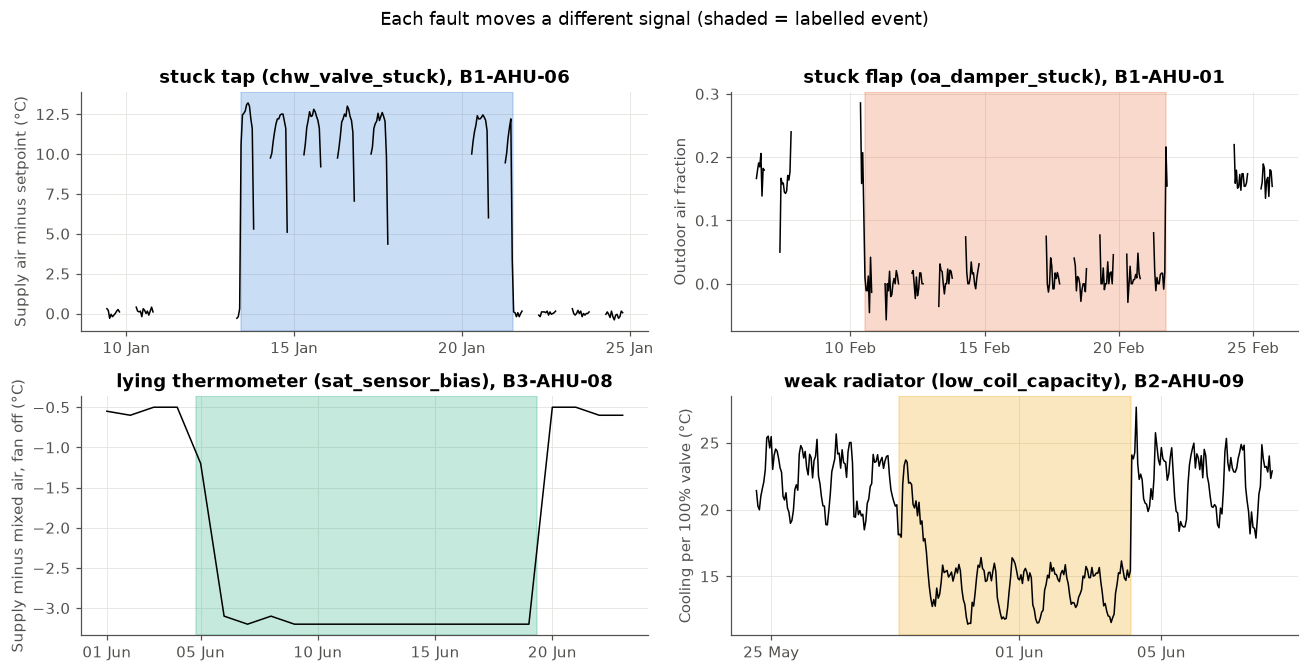

In [5]:
# One event per fault type, and the signal that shows it best
examples = [
    ("chw_valve_stuck", "B1-AHU-06", "sat_error", "Supply air minus setpoint (°C)", "h"),
    ("oa_damper_stuck", "B1-AHU-01", "oa_fraction", "Outdoor air fraction", "h"),
    ("sat_sensor_bias", "B3-AHU-08", "rest_offset", "Supply minus mixed air, fan off (°C)", "D"),
    ("low_coil_capacity", "B2-AHU-09", "cooling_per_valve", "Cooling per 100% valve (°C)", "h"),
]

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for ax, (fault, ahu_id, col, ylabel, step) in zip(axes.flat, examples, strict=True):
    event = labels[(labels["ahu_id"] == ahu_id) & (labels["fault_type"] == fault)].iloc[0]
    window = slice(event["start"] - pd.Timedelta("4D"), event["end"] + pd.Timedelta("4D"))
    # The fan-on signals use rows after start-up; the rest offset uses rows with the fan off
    source = resting if col == "rest_offset" else running
    series = source[source["ahu_id"] == ahu_id].set_index("timestamp")[col].loc[window]
    ax.plot(series.resample(step).median(), color="black", lw=1)
    ax.axvspan(event["start"], event["end"], color=FAULT_COLORS[fault], alpha=0.25)
    ax.set_title(f"{FAULT_NAMES[fault]} ({fault}), {ahu_id}")
    ax.set_ylabel(ylabel)
    # Ticks on fixed days of the month, so labels never overlap at the end of a month
    ax.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1, 5, 10, 15, 20, 25]))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
fig.suptitle("Each fault moves a different signal (shaded = labelled event)", y=1.01)
fig.tight_layout()
save_fig(fig, "04_fault_signatures")
plt.show()

**How to read the chart:**
- **Stuck tap, B1-AHU-06 (January):** the supply air goes from 0 to about +12 °C above its setpoint and stays there until the repair. The valve was stuck nearly closed, so the coil gives almost no cooling.
- **Stuck flap, B1-AHU-01 (February):** the outdoor air fraction falls from about 0.15 to 0 during the event and comes back after. The unit only recirculates indoor air.
- **Lying thermometer, B3-AHU-08 (June):** with the fan off, the supply sensor normally reads 0.5 °C below the mixed air. During the event it reads about 3 °C below. With the fan on, nothing shows: the controller trusts the sensor and keeps the reading on target.
- **Weak radiator, B2-AHU-09 (May-June):** each 100% of valve opening gives less cooling during the event. The supply air stays on target because the valve opens more to make up for it.

## 3. Stuck tap and weak radiator: how to tell them apart

Both are about cooling, and both can make the valve open more. The difference:
- **Weak radiator:** the valve still works. The controller opens it more, and the supply air stays on target until the valve reaches 100%.
- **Stuck tap:** the valve doesn't move. The supply air goes off target right away, warm or cold, and the valve command runs to 0% or 100% because the controller tries to fix it.

In [6]:
# Share of rows with the supply air more than 2 °C off target, and with the command at a limit
running = running.assign(
    off_target=running["sat_error"].abs() > 2,
    command_at_limit=running["chw_valve_cmd_pct"].isin([0, 100]),
)
fault_rows = running[running["label"].isin(["chw_valve_stuck", "low_coil_capacity", "normal"])]
share = fault_rows.groupby("label")[["off_target", "command_at_limit"]].mean()
share.index = [FAULT_NAMES.get(f, f) for f in share.index]
share.map("{:.0%}".format)

,off_target,command_at_limit
stuck tap,97%,99%
weak radiator,16%,20%
normal,2%,4%


**How to read it:** during a stuck tap, the supply air is more than 2 °C off target in most rows and the valve command sits at 0% or 100% most of the time. During a weak radiator, the supply air stays on target in most rows: only when the valve is already at 100% does it drift. Normal rows are a little off target only in the three machines that are always at their limit.

**Obs:** the size of the supply air error and how long the command sits at a limit separate the two faults well, except in the three machines at their limit, where the valve is at 100% anyway.

## 4. The lying thermometer: the hardest one

The controller trusts the sensor. If the sensor reads 2 °C too high, the controller cools the air 2 °C more, so the *reading* is on target. Nothing looks wrong with the fan on: the error is 0.

**My idea:** look at the sensor when the fan is off. With no air moving, the air in the unit is still, so the supply sensor and the mixed air sensor should read almost the same. A sensor that reads too high or too low shows up there. `sat_offset_at_rest()` in `src/ahu_fdd/features.py` gives supply minus mixed air after the fan has been off for one hour.

In [7]:
# Offset at rest in healthy rows, per building (B2 is 24/7, so it never rests)
healthy_rest = resting[resting["label"] == "normal"]
healthy_rest.groupby("building")["rest_offset"].describe()[["count", "mean", "std"]].round(2)

,count,mean,std
building,,,
B1,439606.0,-0.50,0.23
B3,222682.0,-0.51,0.23


In [8]:
# Offset at rest during each lying thermometer event vs the same machine's normal
bias_events = labels[labels["fault_type"] == "sat_sensor_bias"]
rows = []
for event in bias_events.itertuples():
    rest = resting[resting["ahu_id"] == event.ahu_id]
    in_event = (rest["timestamp"] >= event.start) & (rest["timestamp"] < event.end)
    rows.append(
        {
            "ahu_id": event.ahu_id,
            "start": event.start.strftime("%d %b"),
            "during_event": rest.loc[in_event, "rest_offset"].median(),
            "normal": rest.loc[rest["label"] == "normal", "rest_offset"].median(),
        }
    )
pd.DataFrame(rows).round(1)

,ahu_id,start,during_event,normal
0,B3-AHU-02,06 Mar,2.4,-0.5
1,B1-AHU-02,26 Mar,2.0,-0.5
2,B3-AHU-12,15 Apr,-3.1,-0.5
3,B3-AHU-08,04 Jun,-3.2,-0.5
4,B3-AHU-06,09 Jun,-2.5,-0.5
5,B3-AHU-05,18 Jun,2.3,-0.5


**How to read it:** in healthy machines the supply sensor reads 0.5 °C below the mixed air when the fan is off, with very little spread (std 0.2 °C). During the six lying thermometer events it reads +2.0 to +2.4 °C (sensor too high) or -2.5 to -3.2 °C (sensor too low). That is 2.5 °C away from normal, more than 10 times the normal spread.

**Obs:**
- The fault is invisible with the fan on, but clear with the fan off. The bias is about ±2.5 °C.
- The check only works on machines that switch off at night. All six labelled events are in such machines (office and mall). The hospital and the two 24/7 office machines never rest, so a lying thermometer there would be very hard to see.
- It's also slow: the first check comes the night after the fault starts. So detection can be up to a day late.

**Decision:** I keep the last offset at rest of each machine and carry it to the next fan-on rows, as a feature for the model.

## 5. Do the label dates match the data?

The labels come from work orders: the start is the engineer's best guess. **How:** for each event, I find the first and last hour where its fingerprint is clearly on (a simple threshold on the signal from section 2), from 4 days before to 4 days after the event, and compare with the label dates. I skip the weak radiator, whose signal needs the load to compare (it's not a simple threshold).

In [9]:
# A simple "fingerprint on" rule per fault, on hourly medians
rules = {
    "chw_valve_stuck": ("sat_error", lambda s: s.abs() > 2.5),
    "oa_damper_stuck": ("oa_fraction", lambda s: s < 0.03),
    "sat_sensor_bias": ("rest_offset", lambda s: (s + 0.5).abs() > 1.5),
}
rows = []
for event in labels[labels["fault_type"].isin(rules)].itertuples():
    col, is_on = rules[event.fault_type]
    source = resting if col == "rest_offset" else running
    window = slice(event.start - pd.Timedelta("4D"), event.end + pd.Timedelta("4D"))
    hourly = source[source["ahu_id"] == event.ahu_id].set_index("timestamp")[col].loc[window]
    hourly = hourly.resample("h").median().dropna()
    on_hours = hourly.index[is_on(hourly)]
    rows.append(
        {
            "ahu_id": event.ahu_id,
            "fault": FAULT_NAMES[event.fault_type],
            "label_start": event.start,
            "seen_from_h": (on_hours.min() - event.start) / pd.Timedelta("1h"),
            "label_end": event.end,
            "seen_until_h": (on_hours.max() - event.end) / pd.Timedelta("1h"),
        }
    )
dates = pd.DataFrame(rows)
for col in ["label_start", "label_end"]:
    dates[col] = dates[col].dt.strftime("%a %d %b %H:%M")
dates.round(0)

,ahu_id,fault,label_start,seen_from_h,label_end,seen_until_h
0,B2-AHU-01,stuck flap,Thu 02 Jan 05:50,0.0,Tue 07 Jan 20:25,-0.0
1,B1-AHU-06,stuck tap,Mon 13 Jan 10:00,0.0,Tue 21 Jan 12:20,-0.0
2,B3-AHU-09,stuck tap,Thu 16 Jan 06:25,-89.0,Sat 18 Jan 13:25,25.0
3,B1-AHU-01,stuck flap,Mon 10 Feb 12:40,0.0,Fri 21 Feb 17:40,-1.0
4,B1-AHU-03,stuck flap,Mon 24 Feb 13:20,1.0,Sat 01 Mar 04:20,51.0
5,B3-AHU-02,lying thermometer,Thu 06 Mar 03:05,21.0,Sat 15 Mar 14:15,-6.0
6,B1-AHU-04,stuck tap,Mon 24 Mar 09:30,0.0,Mon 31 Mar 11:55,-65.0
7,B1-AHU-02,lying thermometer,Wed 26 Mar 11:45,11.0,Thu 03 Apr 13:20,-7.0
8,B3-AHU-06,stuck tap,Sun 13 Apr 20:25,-0.0,Mon 21 Apr 12:40,-1.0
9,B2-AHU-08,stuck tap,Sun 13 Apr 22:55,0.0,Thu 17 Apr 00:25,-0.0


**How to read it:** `seen_from_h` = hours between the label start and the first hour the fingerprint is on (0 = same hour, positive = seen later, negative = seen before the label). `seen_until_h` is the same for the end.

**Obs:**
- **Stuck tap and stuck flap:** most events match the label within one hour, at both ends. The labels are precise.
- **Office events that seem to end early** (B1-AHU-04 tap: -65 h; B1-AHU-10 flap: -54 h) end on a Monday: the fan is off from Friday evening, so the last fan-on hour with the fault is Friday.
- **B1-AHU-03 flap (+51 h):** the work order says repaired on Saturday at 04:20, but the flap still looks stuck on Monday morning for about an hour. Maybe it was really fixed on Monday morning.
- **Lying thermometer:** seen 11 to 41 hours after the label start, because the check only runs at night with the fan off. This is the detection delay I expect for this fault.
- **Mall events that start at night** (B3-AHU-03 tap, B3-AHU-02 flap: +10 h) are seen when the mall opens in the morning: the fan is off before that.
- **B3-AHU-09 stuck tap:** seen 89 hours before and 25 hours after the label. This machine is always at its limit (notebook 03), so its supply air is often 2-3 °C warm anyway. The fault is hard to separate from its normal.

**Decision:** I trust the label dates. When I score my model per event, I don't punish a lying thermometer found the first night.

## 6. Faults without a label

The labels look accurate, but they may not be complete. **How:** I apply the same fingerprint rules to the rows labelled normal, one value per machine and day, and look for days where a fingerprint is on.

In [10]:
# Daily medians per machine of the healthy-labelled rows
running["day"] = running["timestamp"].dt.date
normal_days = (
    running[running["label"] == "normal"]
    .groupby(["ahu_id", "day"])
    .agg(
        oa_fraction=("oa_fraction", "median"),
        flap_command=("oa_damper_cmd_pct", "median"),
        co2=("co2_ppm", "median"),
        sat_error=("sat_error", "median"),
    )
)

# Stuck flap fingerprint: almost no outdoor air although the command asks for some
flap_days = normal_days[(normal_days["oa_fraction"] < 0.03) & (normal_days["flap_command"] >= 10)]
flap_days.reset_index().groupby("ahu_id")["day"].agg(["min", "max", "size"])

,min,max,size
ahu_id,,,
B1-AHU-11,2025-04-22,2025-04-30,7


In [11]:
# B1-AHU-11 day by day around those dates
b1_11 = normal_days.loc["B1-AHU-11"].loc[pd.Timestamp("2025-04-14").date() :]
b1_11.head(14).astype(float).round(2)

,oa_fraction,flap_command,co2,sat_error
day,,,,
2025-04-14,0.08,15.0,984.0,0.0
2025-04-15,0.08,15.0,985.5,0.0
2025-04-16,0.09,15.0,965.0,0.0
2025-04-17,0.08,15.0,957.0,0.0
2025-04-21,0.08,15.0,988.0,0.0
2025-04-22,0.01,70.0,1733.5,0.0
2025-04-23,0.02,70.0,1661.0,-0.1
2025-04-24,0.02,70.0,1677.5,0.0
2025-04-25,0.01,70.0,1730.0,0.1


**How to read it:** B1-AHU-11 has a normal outdoor air fraction (about 0.08) up to Monday 21 April. From Tuesday 22 to Wednesday 30 April it is almost 0, the flap command jumps from 15% to 70% and CO2 rises from about 980 to about 1,700 ppm. On Friday 2 May everything is normal again (1 May is a public holiday).

Looking at the 5-minute rows (not shown), the fault is there from the morning of 22 April, and on 30 April at about 16:00 the outdoor air fraction jumps back up and CO2 falls from about 1,860 to 1,020 ppm in 30 minutes. That looks like a technician fixing it on site.

**Obs:** this is exactly the fingerprint of the labelled stuck flaps (section 1), during 7 working days, with no work order. It's very likely a real stuck flap that was fixed without a work order, or with one that never reached this dataset.

**Decision:** for training, I mark B1-AHU-11 from 22 April 07:00 to 30 April 16:00 as a stuck flap (`oa_damper_stuck`). Leaving those rows as normal would teach the model that this fingerprint is healthy.

**Ask the operator:** Was there a work order for B1-AHU-11 at the end of April 2025?
Why it matters: if the labels miss faults, the model learns them as normal, and the scoring can count a real fault as a false alarm.

In [12]:
# Same idea for the other fingerprints: stuck tap (excluding the three machines at their limit)
at_limit = ["B1-AHU-05", "B3-AHU-02", "B3-AHU-09"]
tap_days = normal_days[
    (normal_days["sat_error"].abs() > 3) & ~normal_days.index.get_level_values(0).isin(at_limit)
]
print(f"Healthy-labelled days with a stuck tap fingerprint: {len(tap_days)}")
tap_days

Healthy-labelled days with a stuck tap fingerprint: 0


,,oa_fraction,flap_command,co2,sat_error
ahu_id,day,,,,


**How to read it:** zero days. Outside the labelled events and the three machines at their limit, the supply air never stays more than 3 °C off target for a day. No missing stuck tap.

For the lying thermometer, the same check (offset at rest more than 1.5 °C from normal) only fires on the last nights of labelled events. I can't check the weak radiator with a simple rule, because its signal depends on the load: the model will look for it.

## Summary

**The idea.** Notebook 03 showed what a healthy machine looks like, like a doctor who knows your normal temperature. Here I looked at each "illness": which symptoms each fault gives, and whether the 28 labelled faults really have them. I always compare a fault with the healthy days of the same machine.

**1. Each fault has its own symptom.** Like the flu gives fever and a cold gives a runny nose. This is what a model needs to tell the faults apart.
- **Stuck tap** (`chw_valve_stuck`). What happens: the supply air goes far off target, 4 to 12 °C too warm if the valve is stuck nearly closed, or about 5 °C too cold if it's stuck open. The controller pushes the valve command to 0% or 100%, with no effect. Everyday example: you turn the shower tap and the water doesn't change, so you end up turning it all the way.
- **Stuck flap** (`oa_damper_stuck`). What happens: no outdoor air comes in, the controller asks for more (with no effect) and CO2 in the rooms goes up, from about 1,000 to 1,700 ppm. Everyday example: the car window won't open and the air inside gets stuffy.
- **Weak radiator** (`low_coil_capacity`). What happens: the controller opens the valve more to get the same cooling. The supply air stays on target until the valve reaches 100%, and only then it gets warm. Everyday example: an old air conditioner that has to run at full power to cool as much as before.
- **Stuck tap or weak radiator?** With a stuck tap the supply air is off target almost all the time (97% of the rows). With a weak radiator the controller compensates and the air is on target most of the time.

**2. The lying thermometer** (`sat_sensor_bias`) **is the hardest.**
- What happens: the controller trusts the sensor. If it reads 2 °C too high, the controller cools 2 °C more and the reading looks perfect. With the machine running, nothing shows.
- My trick: I look at the sensor after the fan has been off for an hour. With still air, the supply and mixed air sensors should read almost the same. A healthy machine reads 0.5 °C lower at the supply. During the six events it reads 2 to 3 °C higher or lower. Everyday example: to know if a scale lies, you don't weigh anything, you look at it empty. If it shows 2 kg when empty, it lies.
- Limits: it only works on machines that switch off at night, not in the 24/7 hospital. And it's found the first night at the earliest, so up to a day late.

**3. The label dates can be trusted.**
- For the faults I can check, the symptom starts and ends within about an hour of the work order dates.
- The bigger gaps are weekends: the office closes on Friday and the technician repairs on Monday, so the last fan-on row with the fault is Friday.
- Why it matters: with wrong dates, the model would learn from wrongly labelled rows.

**4. A fault nobody wrote down.**
- B1-AHU-11, from 22 to 30 April, has a textbook stuck flap: no outdoor air, the flap command at 70% instead of the usual 15%, and CO2 from 980 to 1,700 ppm.
- On 30 April at about 16:00 the repair shows in the data: in half an hour the outdoor air comes back and CO2 falls. A technician fixed it, but there is no work order.
- Why it matters: if I leave it as normal, the model learns that a stuck flap is healthy. In test, a fault like this would even count as a false alarm.
- Decision: I label it as a stuck flap for training, and I ask the operator.

**5. What will be hard to catch.**
- The lying thermometer in machines that never switch off.
- A stuck tap or a weak radiator in the three machines that are always at their limit (notebook 03). Their valve is at 100% on a normal day, so the fault hides in their daily struggle.

**What this gives the model** (phase 2). Each feature comes from the physics of one fault, and is compared with each machine's own normal: the supply air error (stuck tap), outdoor air fraction and CO2 (stuck flap), cooling per valve (weak radiator) and the last check at rest (lying thermometer).

**In one sentence:** each fault leaves a different fingerprint in the data, the labels are reliable, I found one fault nobody wrote down, and for the lying thermometer I check the sensor with the fan off, because with the machine running it is invisible.